# [Bonus Tasks](svm_segm.ipynb)

In [5]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.ndimage as ndi
import skimage.morphology as morph
import skimage.util
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [6]:
def blend_result(img, seg, border_radius=1, interior_opacity=1, interior_opacity_decay=0.9, color=(0,1,0)):
    img  = np.dstack([img] * 3).copy()
    img -= img.min()
    img /= img.max()
    selem  = morph.disk(border_radius)
    seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))
    mask_decay = ndi.distance_transform_edt(seg)
    for i in range(3):
        opacity = interior_opacity / pow(1 + mask_decay[seg], interior_opacity_decay)
        img[:,:,i][seg] = color[i] * opacity + (1 - opacity) * img[:,:,i][seg]
        img[:,:,i][seg_bd] = color[i]
    return img

In [7]:
patch_sizes = (32, 32)


---

**[Task 1.1.]()** Implement `create_data_matrix`:

In [8]:

    
from skimage.util import view_as_blocks

def create_data_matrix(img):
    h, w = img.shape[:2]
    # auf ein Vielfaches der Patchgröße zuschneiden (view_as_blocks braucht das)
    img = img[:h // patch_sizes[0] * patch_sizes[0],
              :w // patch_sizes[1] * patch_sizes[1]]
    blocks = view_as_blocks(img, patch_sizes)      # (rows, cols, 32, 32)
    return blocks.reshape(-1, patch_sizes[0] * patch_sizes[1])  # (m, 1024)

**[Task 1.2.]()** Implement `create_gt_labels_vector`:

In [9]:
def create_gt_labels_vector(gt):
    gt = gt > 0.5 if gt.dtype != bool else gt
    X = create_data_matrix(gt.astype(float))
    frac = X.mean(axis=1)            # Foreground-Anteil pro Patch
    y = np.zeros(len(frac), dtype=int)
    y[frac > 0.5] = 1
    y[frac == 0] = -1
    return y                          # alles andere bleibt 0

**[Task 1.3.]()** Create the SVM classifier:

In [10]:
clf = make_pipeline(StandardScaler(), SVC(class_weight='balanced', gamma=0.1))

**[Task 1.3 (a).]()** Create the data matrices for the images `dna-33` and `dna-44`:

In [13]:


img33 = plt.imread('data/NIH3T3/im/dna-33.png')
img44 = plt.imread('data/NIH3T3/im/dna-44.png')
X33, X44 = create_data_matrix(img33), create_data_matrix(img44)

**[Task 1.3 (b).]()** Create the corresponding ground truth label vectors:

In [14]:

gt33 = plt.imread('data/NIH3T3/gt/33.png')
gt44 = plt.imread('data/NIH3T3/gt/44.png')
y33, y44 = create_gt_labels_vector(gt33), create_gt_labels_vector(gt44)

**[Task 1.3 (c).]()** Create the *combined* data matrices and ground truth label vectors:

In [15]:
# (c)
X = np.concatenate([X33, X44])
Y = np.concatenate([y33, y44])
keep = Y != 0
X, Y = X[keep], Y[keep]

**[Task 1.3 (d).]()** Train the classifier using the data matrix and label vectors from above:

In [16]:

clf.fit(X, Y)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(class_weight='balanced', gamma=0.1))])

**[Task 1.4.]()** Implement the function `predict_image`:

In [17]:
def predict_image(img):
    X = create_data_matrix(img)
    pred = clf.predict(X)
    rows = img.shape[0] // patch_sizes[0]
    cols = img.shape[1] // patch_sizes[1]
    patch_mask = (pred == 1).reshape(rows, cols)
    # jeden Patch auf Pixelgröße aufblasen
    seg_crop = np.kron(patch_mask, np.ones(patch_sizes, dtype=bool)).astype(bool)
    # auf Originalgröße auffüllen (Rand ohne Patch = False)
    seg = np.zeros(img.shape[:2], dtype=bool)
    seg[:seg_crop.shape[0], :seg_crop.shape[1]] = seg_crop
    return seg

Test your implementation:

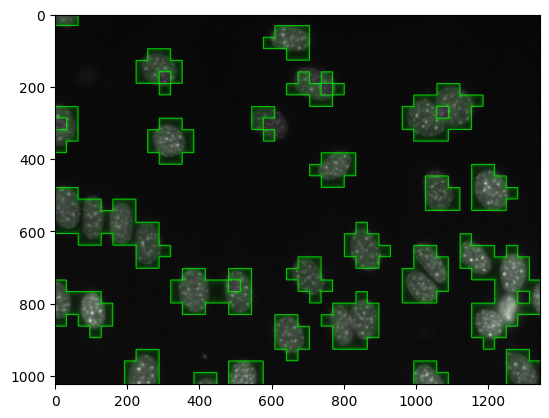

In [21]:
img = plt.imread(f'data/NIH3T3/im/dna-0.png')
seg = predict_image(img)

plt.figure()
plt.imshow(blend_result(img, seg))
plt.show()

**[Task 1.5.]()** Perform batch processing:

Bild 28: Dice = 0.7210
Bild 29: Dice = 0.6601
Bild 33: Dice = 0.6779
Bild 44: Dice = 0.7125
Bild 46: Dice = 0.6171
Bild 49: Dice = 0.6890
Mittlerer Dice: 0.6796
Bild 28: Dice (Otsu) = 0.7529
Bild 29: Dice (Otsu) = 0.6476
Bild 33: Dice (Otsu) = 0.4652
Bild 44: Dice (Otsu) = 0.5758
Bild 46: Dice (Otsu) = 0.0761
Bild 49: Dice (Otsu) = 0.7925
Mittlerer Dice Otsu: 0.5517  vs. SVM: 0.6796


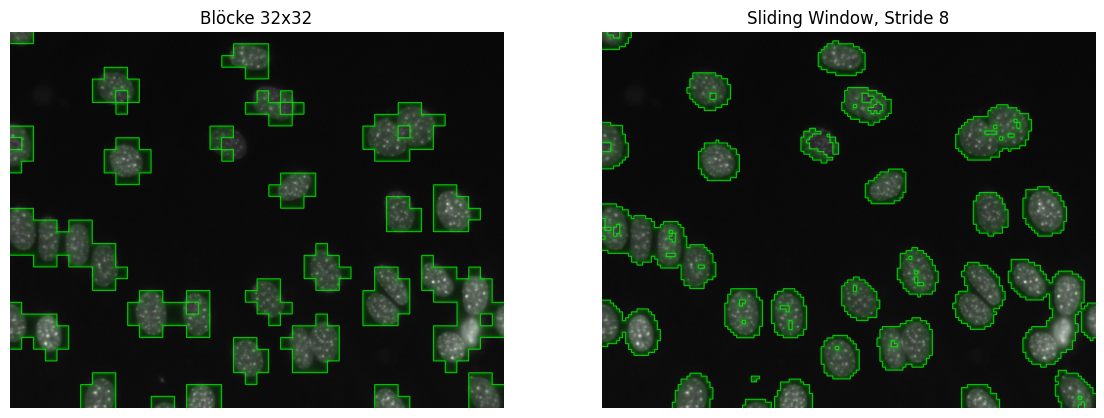

In [26]:
def dice(a, b):
    a, b = a.astype(bool), b.astype(bool)
    return 2 * np.logical_and(a, b).sum() / (a.sum() + b.sum())

dices = []
for i in [28, 29, 33, 44, 46, 49]:
    img = plt.imread(f'data/NIH3T3/im/dna-{i}.png')
    gt  = plt.imread(f'data/NIH3T3/gt/{i}.png')
    gt = gt > 0.5
    seg = predict_image(img)
    d = dice(seg, gt)
    dices.append(d)
    print(f'Bild {i}: Dice = {d:.4f}')
print(f'Mittlerer Dice: {np.mean(dices):.4f}')

from skimage.filters import threshold_otsu

dices_otsu = []
for i in [28, 29, 33, 44, 46, 49]:
    img = plt.imread(f'data/NIH3T3/im/dna-{i}.png')
    gt  = plt.imread(f'data/NIH3T3/gt/{i}.png') > 0.5
    seg = img > threshold_otsu(img)
    d = dice(seg, gt)
    dices_otsu.append(d)
    print(f'Bild {i}: Dice (Otsu) = {d:.4f}')
print(f'Mittlerer Dice Otsu: {np.mean(dices_otsu):.4f}  vs. SVM: {np.mean(dices):.4f}')



# aufgabe 2
from skimage.util import view_as_windows
from skimage.transform import resize

def predict_image_sw(img, stride=8):
    n = patch_sizes[0]
    pad = n // 2
    padded = np.pad(img, pad, mode='reflect')
    win = view_as_windows(padded, (n, n), step=stride)   # (r, c, n, n)
    r, c = win.shape[:2]
    pred = clf.predict(win.reshape(-1, n * n)).reshape(r, c) == 1
    seg = resize(pred.astype(float), img.shape[:2], order=0) > 0.5
    return seg



# test und vergleich
img = plt.imread('data/NIH3T3/im/dna-0.png')

seg_blocks = predict_image(img)
seg_sw     = predict_image_sw(img, stride=8)

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(blend_result(img, seg_blocks)); ax[0].set_title('Blöcke 32x32')
ax[1].imshow(blend_result(img, seg_sw));     ax[1].set_title('Sliding Window, Stride 8')
for a in ax: a.axis('off')
plt.show()